# E-Commerce Customer Churn & Retention Analysis

**Dataset:** `eCommerce-dataset.csv` (50,000 customers, 25 columns)
**Goal:** Turn raw customer data into actionable retention strategy.

> Siapa yang churn, pola perilaku apa yang berkaitan dengan churn, customer mana yang paling penting untuk dipertahankan, dan tindakan apa yang sebaiknya dilakukan perusahaan?


## 01. Business Understanding

**Business Problem**
Perusahaan e-commerce ingin memahami customer churn dan menentukan customer mana yang perlu diprioritaskan untuk retention.

**Business Objective**
Mengidentifikasi pola customer behavior yang berkaitan dengan churn serta menerjemahkannya menjadi strategi retention yang dapat dijalankan.

**Analytical Scope:** customer profile, engagement, purchase behavior, recency, customer value, churn, segmentation, retention prioritization.

**Out of Scope** (tidak disimpulkan dalam notebook ini):
- Causal relationship secara definitif
- Alasan psikologis customer
- Profitabilitas aktual (data biaya/margin tidak tersedia)
- Efektivitas campaign yang belum diuji

Seluruh temuan disampaikan dengan bahasa **association / pattern / indication**, bukan causal claim.


## 02. Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

RANDOM_STATE = 42
pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')

df = pd.read_csv("eCommerce-dataset.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()


Rows: 50000
Columns: 25


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14,27.4,6.0,50.6,3.0,9.0,94.72,34.0,46.40,2.0,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15,42.7,10.3,37.7,1.0,19.5,82.45,71.0,57.96,9.2,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10,24.8,1.6,70.9,1.0,9.1,165.52,11.0,12.24,11.5,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10,38.4,14.8,41.7,9.0,15.0,147.33,47.0,44.10,5.4,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29,51.4,NaN,19.1,9.0,32.5,141.30,73.0,25.20,5.5,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4


In [2]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            47505 non-null  float64
 1   Gender                         50000 non-null  str    
 2   Country                        50000 non-null  str    
 3   City                           50000 non-null  str    
 4   Membership_Years               50000 non-null  float64
 5   Login_Frequency                50000 non-null  int64  
 6   Session_Duration_Avg           46601 non-null  float64
 7   Pages_Per_Session              47000 non-null  float64
 8   Cart_Abandonment_Rate          50000 non-null  float64
 9   Wishlist_Items                 46000 non-null  float64
 10  Total_Purchases                50000 non-null  float64
 11  Average_Order_Value            50000 non-null  float64
 12  Days_Since_Last_Purchase       47000 non-null  float64
 1

In [3]:
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,47505.0,NaN,NaN,NaN,37.802968,11.834668,5.0,29.0,38.0,46.0,200.0
Gender,50000,3,Female,25116,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,50000,8,USA,17384,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,50000,40,Houston,3549,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Membership_Years,50000.0,NaN,NaN,NaN,2.984009,2.059105,0.1,1.4,2.5,4.0,10.0
Login_Frequency,50000.0,NaN,NaN,NaN,11.62466,7.810657,0.0,6.0,11.0,17.0,46.0
Session_Duration_Avg,46601.0,NaN,NaN,NaN,27.660754,10.871013,1.0,19.7,26.8,34.7,75.6
Pages_Per_Session,47000.0,NaN,NaN,NaN,8.737811,3.77822,1.0,6.0,8.4,11.2,24.1
Cart_Abandonment_Rate,50000.0,NaN,NaN,NaN,57.079973,16.282723,0.0,46.4,58.1,68.7,143.74335
Wishlist_Items,46000.0,NaN,NaN,NaN,4.298391,3.189754,0.0,2.0,4.0,6.0,28.0


## 03. Data Understanding — Data Dictionary

| Column | Type | Business Meaning | Analytical Role |
|---|---|---|---|
| Age | Numeric | Customer age | Demographic |
| Gender | Categorical | Customer gender | Demographic |
| Country | Categorical | Customer country | Geographic |
| City | Categorical | Customer city | Geographic |
| Membership_Years | Numeric | Tenure with platform | Loyalty |
| Login_Frequency | Numeric | Login activity | Engagement |
| Session_Duration_Avg | Numeric | Avg. session length (min) | Engagement |
| Pages_Per_Session | Numeric | Browsing depth | Engagement |
| Cart_Abandonment_Rate | Numeric (%) | Cart abandonment ratio | Purchase friction |
| Wishlist_Items | Numeric | Items wishlisted | Engagement |
| Total_Purchases | Numeric | Number of purchases | Frequency |
| Average_Order_Value | Numeric | Avg. order value | Monetary |
| Days_Since_Last_Purchase | Numeric | Recency | Recency |
| Discount_Usage_Rate | Numeric (%) | Discount reliance | Purchase behavior |
| Returns_Rate | Numeric (%) | Return ratio | Purchase behavior |
| Email_Open_Rate | Numeric (%) | Email engagement | Engagement |
| Customer_Service_Calls | Numeric | Support contact volume | Service |
| Product_Reviews_Written | Numeric | Review activity | Engagement |
| Social_Media_Engagement_Score | Numeric | Social engagement | Engagement |
| Mobile_App_Usage | Numeric | Mobile app activity | Engagement |
| Payment_Method_Diversity | Numeric | # payment methods used | Behavior |
| Lifetime_Value | Numeric | Customer value | Monetary |
| Credit_Balance | Numeric | Stored credit/balance | Monetary |
| Churned | Binary (0/1) | Churn status — **TARGET** | Target |
| Signup_Quarter | Categorical | Quarter of signup | Cohort |

**Catatan:** definisi final kolom ambigu (mis. Credit_Balance) seharusnya dikonfirmasi dari data dictionary resmi perusahaan; di sini digunakan interpretasi yang masuk akal secara bisnis tanpa mengarang detail yang tidak dapat diverifikasi.


In [4]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()
print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)


Numeric columns: ['Age', 'Membership_Years', 'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Wishlist_Items', 'Total_Purchases', 'Average_Order_Value', 'Days_Since_Last_Purchase', 'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate', 'Customer_Service_Calls', 'Product_Reviews_Written', 'Social_Media_Engagement_Score', 'Mobile_App_Usage', 'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance', 'Churned']
Categorical columns: ['Gender', 'Country', 'City', 'Signup_Quarter']


## 04. Data Quality Assessment

### 04.1 Duplicate Check

In [5]:
dupe_count = df.duplicated().sum()
print("Duplicate rows:", dupe_count)


Duplicate rows: 0


> No duplicate records were detected (if count above is 0).

### 04.2 Missing Values

In [6]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
}).sort_values("missing_pct", ascending=False)
missing = missing[missing["missing_count"] > 0]
missing


,missing_count,missing_pct
Social_Media_Engagement_Score,6000,12.00
Credit_Balance,5500,11.00
Mobile_App_Usage,5000,10.00
Returns_Rate,4491,8.98
Wishlist_Items,4000,8.00
Product_Reviews_Written,3500,7.00
Discount_Usage_Rate,3500,7.00
Session_Duration_Avg,3399,6.80
Pages_Per_Session,3000,6.00
Days_Since_Last_Purchase,3000,6.00


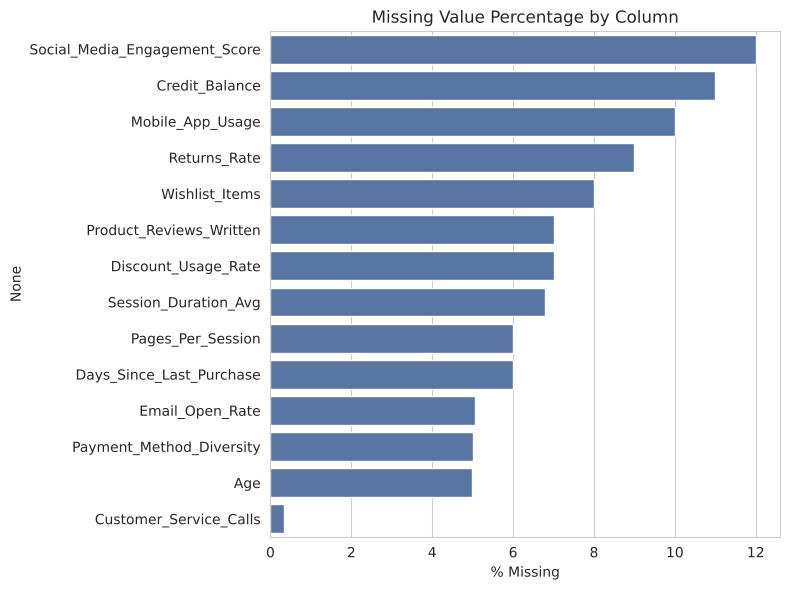

In [7]:
plt.figure(figsize=(8,6))
sns.barplot(x=missing["missing_pct"], y=missing.index, color="#4C72B0")
plt.title("Missing Value Percentage by Column")
plt.xlabel("% Missing")
plt.tight_layout()
plt.show()


### 04.3 Missing Value Decision

Setiap kolom dengan missing value dievaluasi berdasarkan business meaning sebelum treatment ditentukan, bukan otomatis diisi median.

| Variable | Missing % | Likely Reason | Treatment | Justification |
|---|---|---|---|---|
| Age | ~5% | Not provided at signup | Median imputation + missing flag | Age is demographic context, not behavior; median is robust to outliers |
| Session_Duration_Avg | ~7% | Session not tracked / app-only user | Median imputation | Numeric engagement metric, low missing % |
| Pages_Per_Session | ~6% | Same as above | Median imputation | Same reasoning |
| Wishlist_Items | ~8% | Feature not used by customer | **Fill with 0** | Missing likely means "no wishlist activity", not unknown |
| Days_Since_Last_Purchase | ~6% | No purchase yet / not tracked | Median imputation + flag | Could indicate never purchased; flagged for transparency |
| Discount_Usage_Rate | ~7% | Customer never used discount | **Fill with 0** | Missing is informative — no discount usage |
| Returns_Rate | ~9% | No returns made | **Fill with 0** | Missing likely means zero returns |
| Email_Open_Rate | ~5% | Not subscribed to email | Median imputation + flag | Ambiguous — kept as imputed with flag |
| Customer_Service_Calls | <1% | Rarely missing | Median imputation | Negligible impact |
| Product_Reviews_Written | ~7% | No reviews written | **Fill with 0** | Missing is informative — no review activity |
| Social_Media_Engagement_Score | ~12% | Not connected to social media | Median imputation + flag | Larger % — kept visible via flag |
| Mobile_App_Usage | ~10% | Does not use mobile app | **Fill with 0** | Missing likely means no app usage |
| Payment_Method_Diversity | ~5% | Only one payment method on file | Median imputation | Low missing %, continuous-like |
| Credit_Balance | ~11% | No stored credit/balance | **Fill with 0** | Missing likely means zero balance |

Prinsip: variabel yang secara bisnis "tidak digunakan = 0" (wishlist, discount, returns, reviews, mobile usage, credit balance) diisi 0, bukan median, karena median akan mendistorsi makna bisnisnya. Variabel yang bersifat kontinu umum (age, session, pages, recency, email, social) diisi median dan diberi flag agar transparan.


In [8]:
df_clean = df.copy()

zero_fill_cols = ["Wishlist_Items", "Discount_Usage_Rate", "Returns_Rate",
                   "Product_Reviews_Written", "Mobile_App_Usage", "Credit_Balance"]
median_fill_cols = ["Age", "Session_Duration_Avg", "Pages_Per_Session",
                     "Days_Since_Last_Purchase", "Email_Open_Rate",
                     "Customer_Service_Calls", "Social_Media_Engagement_Score",
                     "Payment_Method_Diversity"]

for c in zero_fill_cols:
    df_clean[c] = df_clean[c].fillna(0)

for c in median_fill_cols:
    df_clean[f"{c}_was_missing"] = df_clean[c].isna().astype(int)
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())

print("Remaining missing values:\n", df_clean.isna().sum().sum())


Remaining missing values:
 0


### 04.4 Range Validation

In [9]:
rate_columns = ["Cart_Abandonment_Rate", "Discount_Usage_Rate",
                 "Returns_Rate", "Email_Open_Rate"]

for col in rate_columns:
    print(f"{col}: min={df_clean[col].min():.2f}, max={df_clean[col].max():.2f}")


Cart_Abandonment_Rate: min=0.00, max=143.74
Discount_Usage_Rate: min=0.00, max=116.64
Returns_Rate: min=0.00, max=99.62
Email_Open_Rate: min=0.00, max=91.70


**Catatan:** Jika terdapat rate di atas 100, kemungkinan ada isu unit/data entry. Nilai tersebut **tidak langsung dihapus**, melainkan ditandai untuk investigasi lanjutan (lihat sel berikut).

In [10]:
range_issues = {}
for col in rate_columns:
    n_over = (df_clean[col] > 100).sum()
    if n_over > 0:
        range_issues[col] = n_over
print("Rate columns with values > 100:", range_issues if range_issues else "None found")


Rate columns with values > 100: {'Cart_Abandonment_Rate': np.int64(30), 'Discount_Usage_Rate': np.int64(207)}


### 04.5 Outlier Investigation

In [11]:
outlier_check_cols = ["Age", "Lifetime_Value", "Average_Order_Value",
                       "Total_Purchases", "Days_Since_Last_Purchase",
                       "Login_Frequency", "Session_Duration_Avg", "Cart_Abandonment_Rate"]
df_clean[outlier_check_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
Age,50000.0,37.812800,11.535688,5.00,30.0000,38.000,45.00,200.000000
Lifetime_Value,50000.0,1440.626292,907.249443,0.00,789.8175,1243.415,1874.00,8987.240000
Average_Order_Value,50000.0,123.117330,175.569714,26.38,87.0500,112.970,144.44,9666.379178
Total_Purchases,50000.0,13.111576,7.017312,-13.00,8.0000,12.000,17.00,128.700000
Days_Since_Last_Purchase,50000.0,29.265300,28.866043,0.00,9.0000,21.000,39.00,287.000000
Login_Frequency,50000.0,11.624660,7.810657,0.00,6.0000,11.000,17.00,46.000000
Session_Duration_Avg,50000.0,27.602240,10.497234,1.00,20.2000,26.800,34.00,75.600000
Cart_Abandonment_Rate,50000.0,57.079973,16.282723,0.00,46.4000,58.100,68.70,143.743350


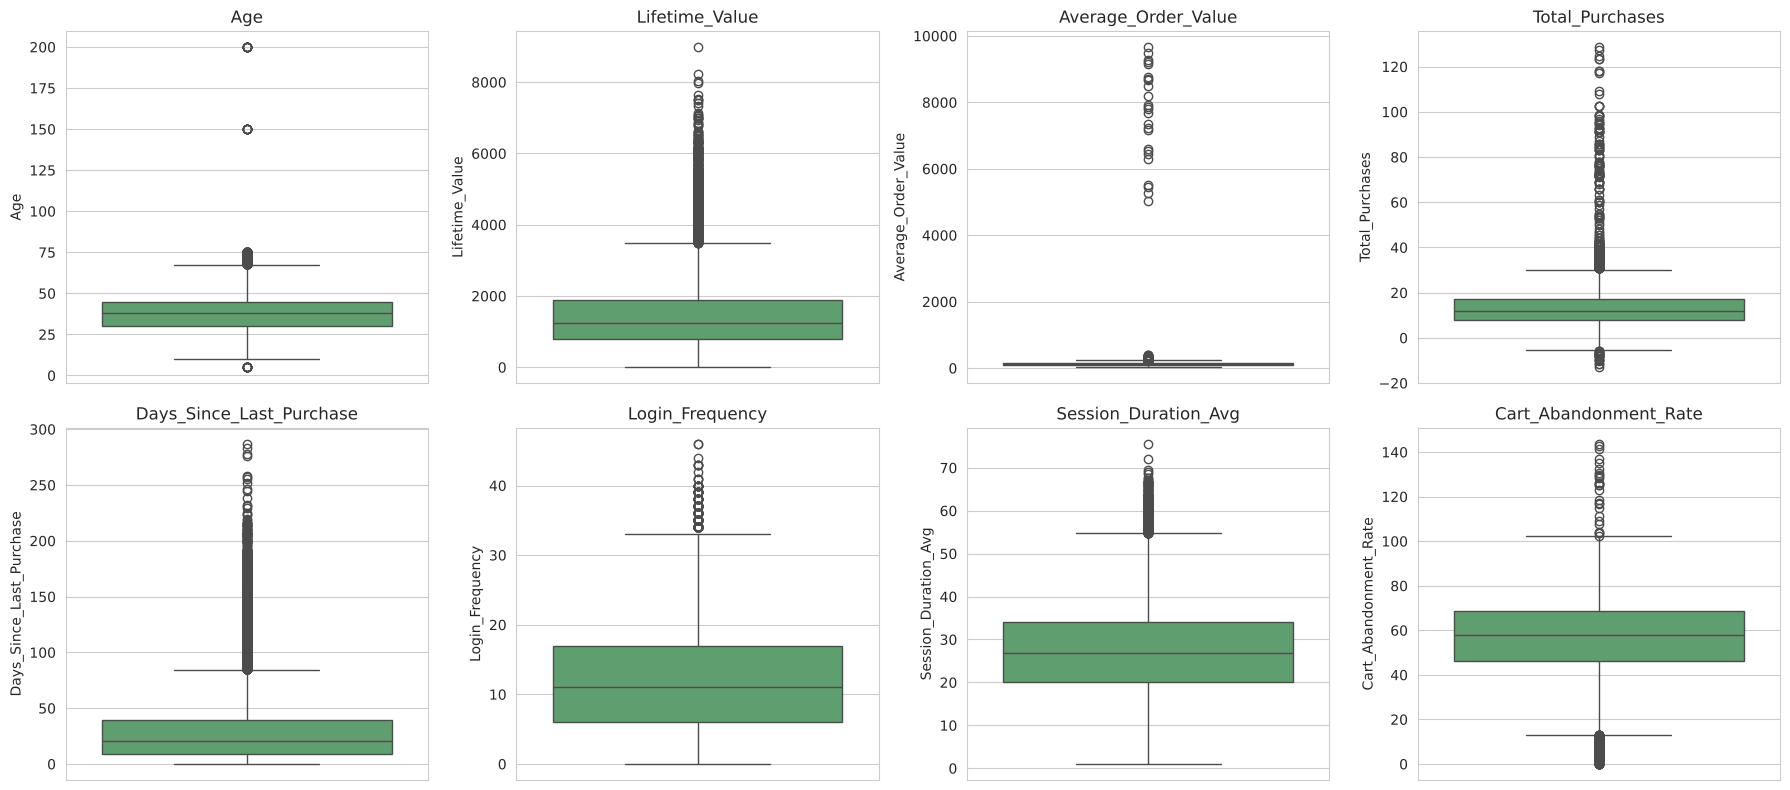

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), outlier_check_cols):
    sns.boxplot(y=df_clean[col], ax=ax, color="#55A868")
    ax.set_title(col)
plt.tight_layout()
plt.show()


**Principle: Outlier ≠ automatically error.** Nilai ekstrem pada Age, Lifetime_Value, atau Total_Purchases dapat mencerminkan customer VIP yang valid. Tidak ada baris yang dihapus pada tahap ini — outlier dicatat sebagai bagian dari data quality log untuk transparansi, dan ditangani dengan binning/quantile pada tahap segmentation agar robust terhadap skew.

### Data Quality Log

| Issue | Detection | Treatment | Reason |
|---|---|---|---|
| Missing (behavioral, 0-meaningful) | Wishlist, Discount, Returns, Reviews, Mobile, Credit | Fill with 0 | Missing indicates "not used" |
| Missing (continuous) | Age, Session, Pages, Recency, Email, Social, Service Calls, Payment Diversity | Median imputation + missing flag | Preserve transparency, robust to skew |
| Duplicate | Checked via `df.duplicated()` | Drop if any found | Avoid double-counting customers |
| Rate > 100 | Checked on 4 rate columns | Flagged, not deleted | Possible unit/entry issue, needs business confirmation |
| Outlier (Age, LTV, etc.) | Boxplot + describe() | Retained, monitored | Could represent valid VIP/edge customers |


## 05. Data Preparation

In [13]:
# Lineage: df (raw) -> df_clean (quality-fixed) -> df_analysis (feature-enriched)
df_analysis = df_clean.copy()

# Age groups
age_bins = [0, 18, 25, 35, 45, 55, 65, 100, np.inf]
age_labels = ["<18", "18-24", "25-34", "35-44", "45-54", "55-64", "65-99", "100+"]
df_analysis["Age_Group"] = pd.cut(df_analysis["Age"], bins=age_bins, labels=age_labels, right=False)

# Recency bands
recency_bins = [-1, 30, 60, 90, 180, np.inf]
recency_labels = ["0-30 days", "31-60 days", "61-90 days", "91-180 days", "180+ days"]
df_analysis["Recency_Band"] = pd.cut(df_analysis["Days_Since_Last_Purchase"], bins=recency_bins, labels=recency_labels)

# Customer value bands (quantile-based — no business-defined threshold available)
df_analysis["Value_Band"] = pd.qcut(df_analysis["Lifetime_Value"], q=3, labels=["Low Value", "Medium Value", "High Value"])

print("Age groups:\n", df_analysis["Age_Group"].value_counts().sort_index())
print("\nRecency bands:\n", df_analysis["Recency_Band"].value_counts().sort_index())
print("\nValue bands:\n", df_analysis["Value_Band"].value_counts())


Age groups:
 Age_Group
<18         30
18-24     6637
25-34    12382
35-44    17640
45-54     9548
55-64     3187
65-99      556
100+        20
Name: count, dtype: int64

Recency bands:
 Recency_Band
0-30 days      33108
31-60 days     10831
61-90 days      3810
91-180 days     2135
180+ days        116
Name: count, dtype: int64

Value bands:
 Value_Band
Low Value       16667
High Value      16667
Medium Value    16666
Name: count, dtype: int64


## 06. Customer Base Analysis

**Question:** Siapa pelanggan kita sebelum menganalisis mengapa mereka churn?


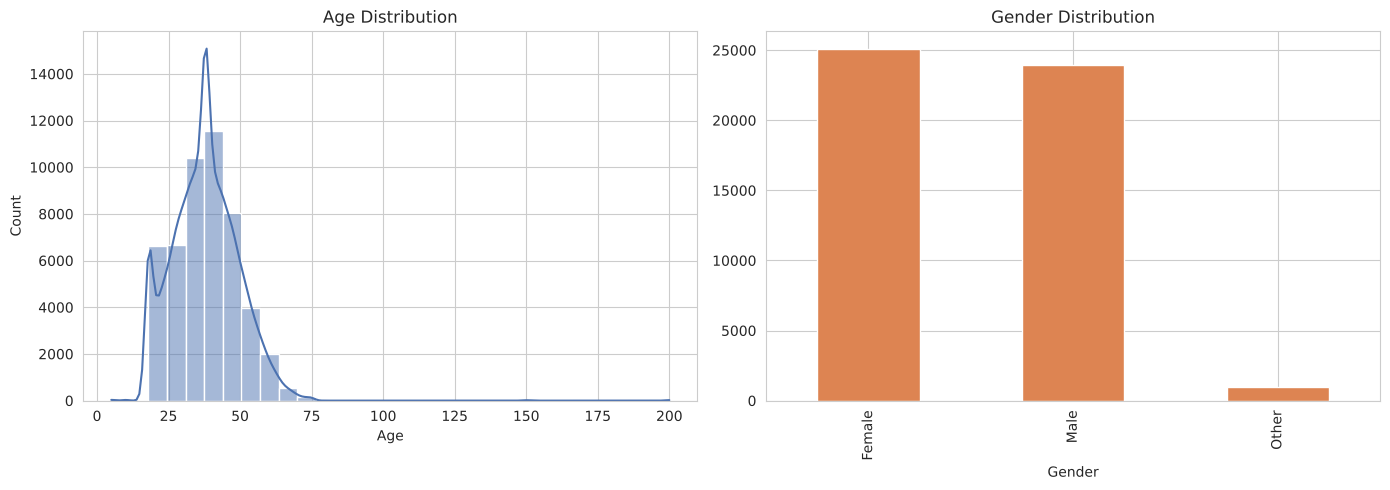

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_analysis["Age"], bins=30, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Age Distribution")
df_analysis["Gender"].value_counts().plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title("Gender Distribution")
plt.tight_layout()
plt.show()


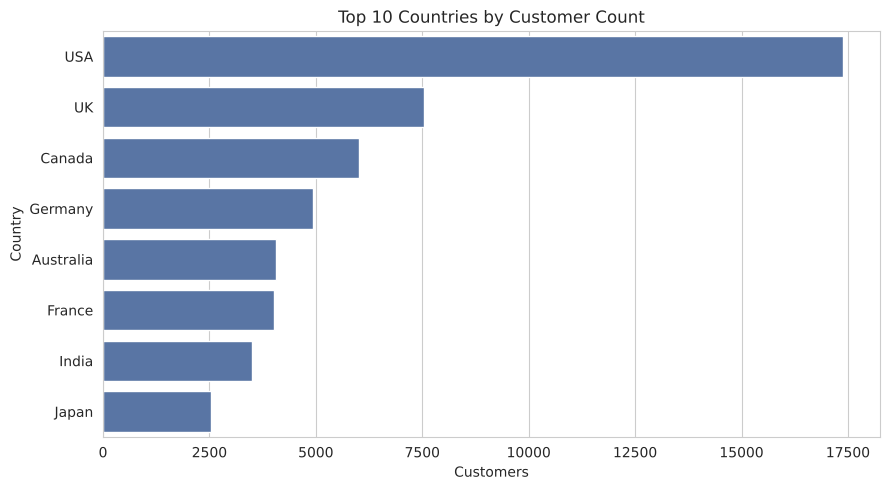

In [15]:
top_countries = df_analysis["Country"].value_counts().head(10)
plt.figure(figsize=(9,5))
sns.barplot(x=top_countries.values, y=top_countries.index, color="#4C72B0")
plt.title("Top 10 Countries by Customer Count")
plt.xlabel("Customers")
plt.tight_layout()
plt.show()


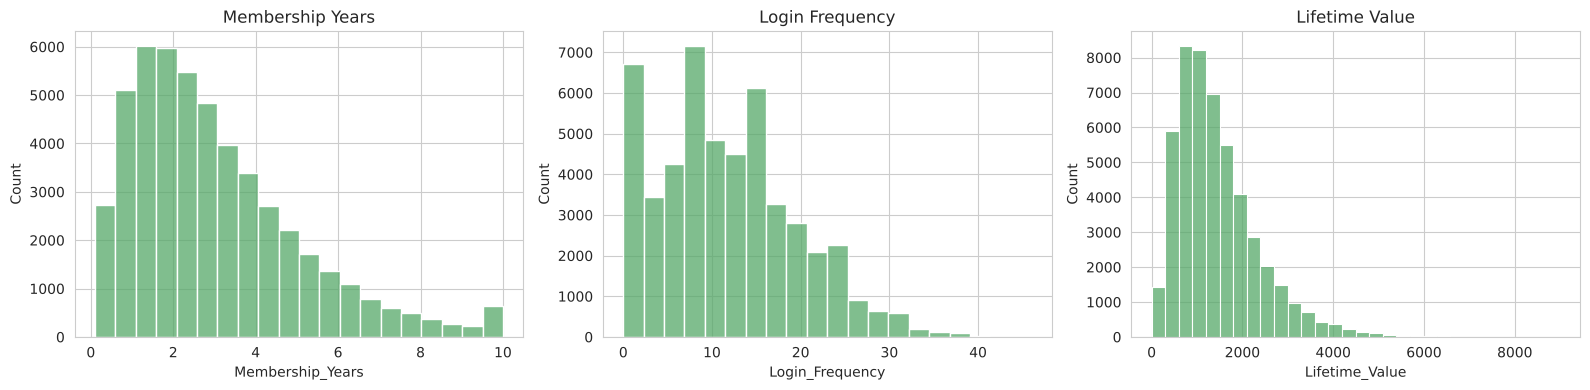

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
sns.histplot(df_analysis["Membership_Years"], bins=20, ax=axes[0], color="#55A868")
axes[0].set_title("Membership Years")
sns.histplot(df_analysis["Login_Frequency"], bins=20, ax=axes[1], color="#55A868")
axes[1].set_title("Login Frequency")
sns.histplot(df_analysis["Lifetime_Value"], bins=30, ax=axes[2], color="#55A868")
axes[2].set_title("Lifetime Value")
plt.tight_layout()
plt.show()


**Finding:** Customer base tersebar across multiple countries dengan demografi usia yang relatif merata, dan distribusi Lifetime Value yang right-skewed — sebagian besar customer bernilai moderat, dengan long tail customer bernilai tinggi.

## 07. Churn Analysis

### 07.1 Overall Churn Rate

In [17]:
churn_rate = df_analysis["Churned"].mean()
print(f"Overall churn rate: {churn_rate:.2%}")
print(f"Churned customers: {df_analysis['Churned'].sum():,}")
print(f"Retained customers: {(df_analysis['Churned']==0).sum():,}")


Overall churn rate: 28.90%
Churned customers: 14,450
Retained customers: 35,550


> **Interpretation:** Out of every 100 customers, approximately X are classified as churned (lihat angka di atas). Ini menjadi baseline untuk seluruh analisis berikutnya.

### 07.2 Churn by Demographics

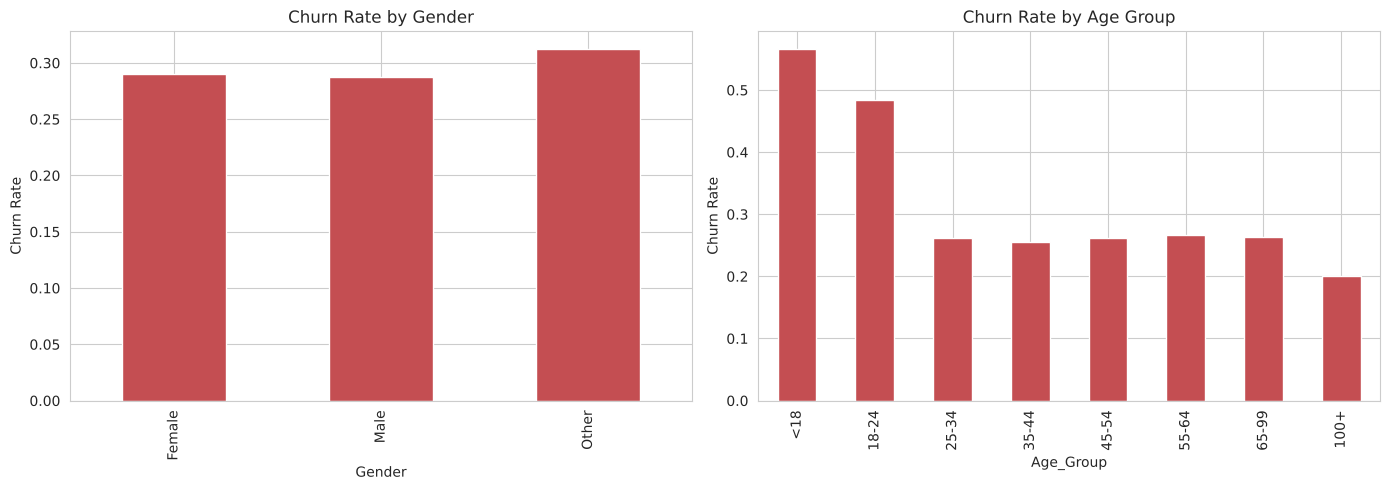

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
df_analysis.groupby("Gender")["Churned"].mean().plot(kind="bar", ax=axes[0], color="#C44E52")
axes[0].set_title("Churn Rate by Gender")
axes[0].set_ylabel("Churn Rate")

df_analysis.groupby("Age_Group", observed=True)["Churned"].mean().plot(kind="bar", ax=axes[1], color="#C44E52")
axes[1].set_title("Churn Rate by Age Group")
axes[1].set_ylabel("Churn Rate")
plt.tight_layout()
plt.show()


### 07.3 Churn by Geography

In [19]:
MIN_SAMPLE = 100  # minimum-count rule to avoid unstable ranking on tiny samples
country_churn = (
    df_analysis.groupby("Country")["Churned"]
    .agg(["count", "mean"])
    .rename(columns={"count": "customers", "mean": "churn_rate"})
)
country_churn = country_churn[country_churn["customers"] >= MIN_SAMPLE].sort_values("churn_rate", ascending=False)
country_churn


,customers,churn_rate
Country,,
Australia,4061,0.298941
Canada,6023,0.293541
USA,17384,0.290842
India,3512,0.290148
Germany,4925,0.288325
UK,7534,0.287895
Japan,2548,0.278257
France,4013,0.272863


> Ranking churn by country hanya dilakukan pada negara dengan sample size memadai (≥100 customers) untuk menghindari kesimpulan yang tidak stabil dari sample kecil. Perbedaan churn antar negara ditafsirkan sebagai *pattern*, bukan penyebab.

### 07.4 Churn by Membership Duration

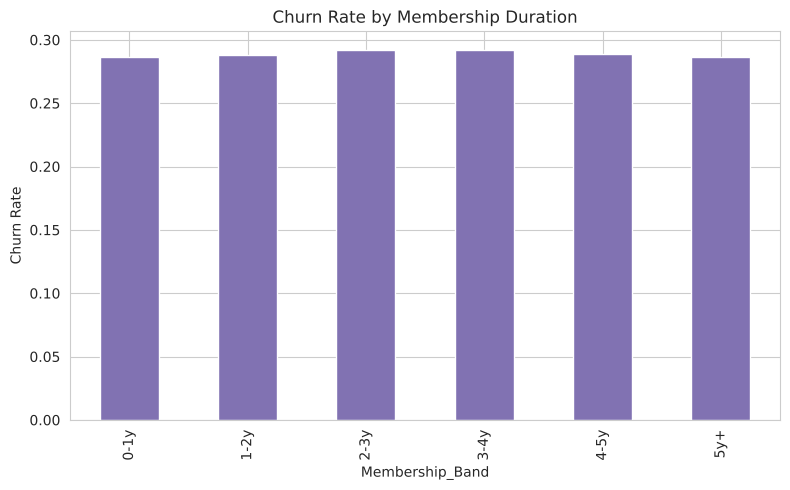

In [20]:
df_analysis["Membership_Band"] = pd.cut(
    df_analysis["Membership_Years"],
    bins=[0,1,2,3,4,5,np.inf],
    labels=["0-1y","1-2y","2-3y","3-4y","4-5y","5y+"]
)
membership_churn = df_analysis.groupby("Membership_Band", observed=True)["Churned"].mean()
membership_churn.plot(kind="bar", figsize=(8,5), color="#8172B2")
plt.title("Churn Rate by Membership Duration")
plt.ylabel("Churn Rate")
plt.tight_layout()
plt.show()


### 07.5 Churn by Purchase Recency

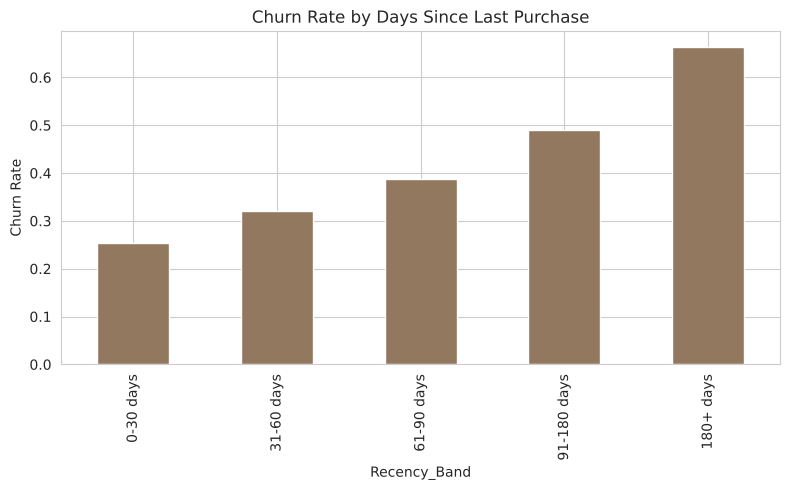

Recency_Band
0-30 days      0.253232
31-60 days     0.320469
61-90 days     0.386614
91-180 days    0.489461
180+ days      0.663793
Name: Churned, dtype: float64

In [21]:
recency_churn = df_analysis.groupby("Recency_Band", observed=True)["Churned"].mean()
recency_churn.plot(kind="bar", figsize=(8,5), color="#937860")
plt.title("Churn Rate by Days Since Last Purchase")
plt.ylabel("Churn Rate")
plt.tight_layout()
plt.show()
recency_churn


> **Finding:** Jika churn rate meningkat seiring bertambahnya recency band, ini mengindikasikan inaktivitas pembelian sebagai sinyal early warning untuk churn.

### 07.6 Churn by Customer Value

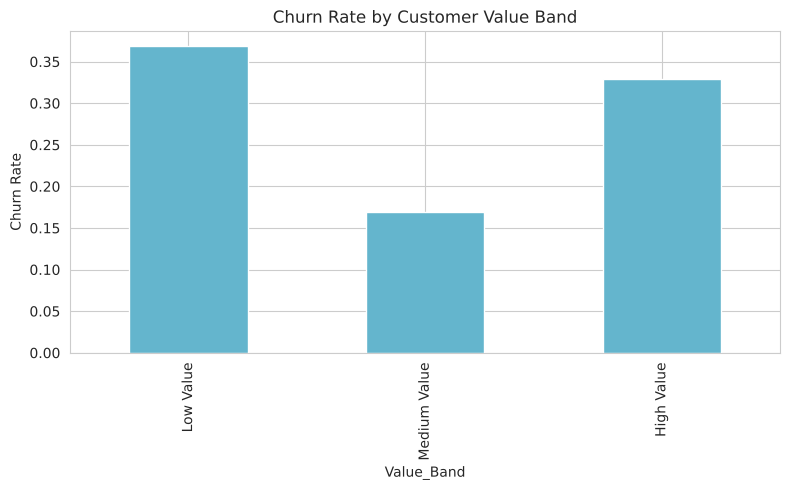

Value_Band
Low Value       0.368393
Medium Value    0.168907
High Value      0.329693
Name: Churned, dtype: float64

In [22]:
value_churn = df_analysis.groupby("Value_Band", observed=True)["Churned"].mean()
value_churn.plot(kind="bar", figsize=(8,5), color="#64B5CD")
plt.title("Churn Rate by Customer Value Band")
plt.ylabel("Churn Rate")
plt.tight_layout()
plt.show()
value_churn


## 08. Behavioral Analysis

In [23]:
behavior_cols = ["Login_Frequency", "Session_Duration_Avg", "Pages_Per_Session",
                  "Mobile_App_Usage", "Email_Open_Rate", "Social_Media_Engagement_Score",
                  "Cart_Abandonment_Rate", "Discount_Usage_Rate", "Returns_Rate"]

comparison = df_analysis.groupby("Churned")[behavior_cols].median().T
comparison.columns = ["Retained (0)", "Churned (1)"]
comparison["Difference"] = comparison["Churned (1)"] - comparison["Retained (0)"]
comparison


,Retained (0),Churned (1),Difference
Login_Frequency,12.0,8.0,-4.0
Session_Duration_Avg,27.4,23.6,-3.8
Pages_Per_Session,8.7,7.2,-1.5
Mobile_App_Usage,18.7,13.5,-5.2
Email_Open_Rate,21.1,14.9,-6.2
Social_Media_Engagement_Score,27.6,23.8,-3.8
Cart_Abandonment_Rate,55.5,66.6,11.1
Discount_Usage_Rate,39.3,34.3,-5.0
Returns_Rate,4.7,5.4,0.7


/tmp/ipykernel_197/987709827.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_analysis, x="Churned", y=col, ax=ax, palette=["#55A868","#C44E52"])
/tmp/ipykernel_197/987709827.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_analysis, x="Churned", y=col, ax=ax, palette=["#55A868","#C44E52"])
/tmp/ipykernel_197/987709827.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_analysis, x="Churned", y=col, ax=ax, palette=["#55A868","#C44E52"])


/tmp/ipykernel_197/987709827.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_analysis, x="Churned", y=col, ax=ax, palette=["#55A868","#C44E52"])
/tmp/ipykernel_197/987709827.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_analysis, x="Churned", y=col, ax=ax, palette=["#55A868","#C44E52"])
/tmp/ipykernel_197/987709827.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_analysis, x="Churned", y=col, ax=ax, palette=["#55A868","#C44E52"])
/tmp/ipykernel_197/987709827.py:3: FutureWarning: 

Passing `palette` withou

/tmp/ipykernel_197/987709827.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_analysis, x="Churned", y=col, ax=ax, palette=["#55A868","#C44E52"])
/tmp/ipykernel_197/987709827.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_analysis, x="Churned", y=col, ax=ax, palette=["#55A868","#C44E52"])


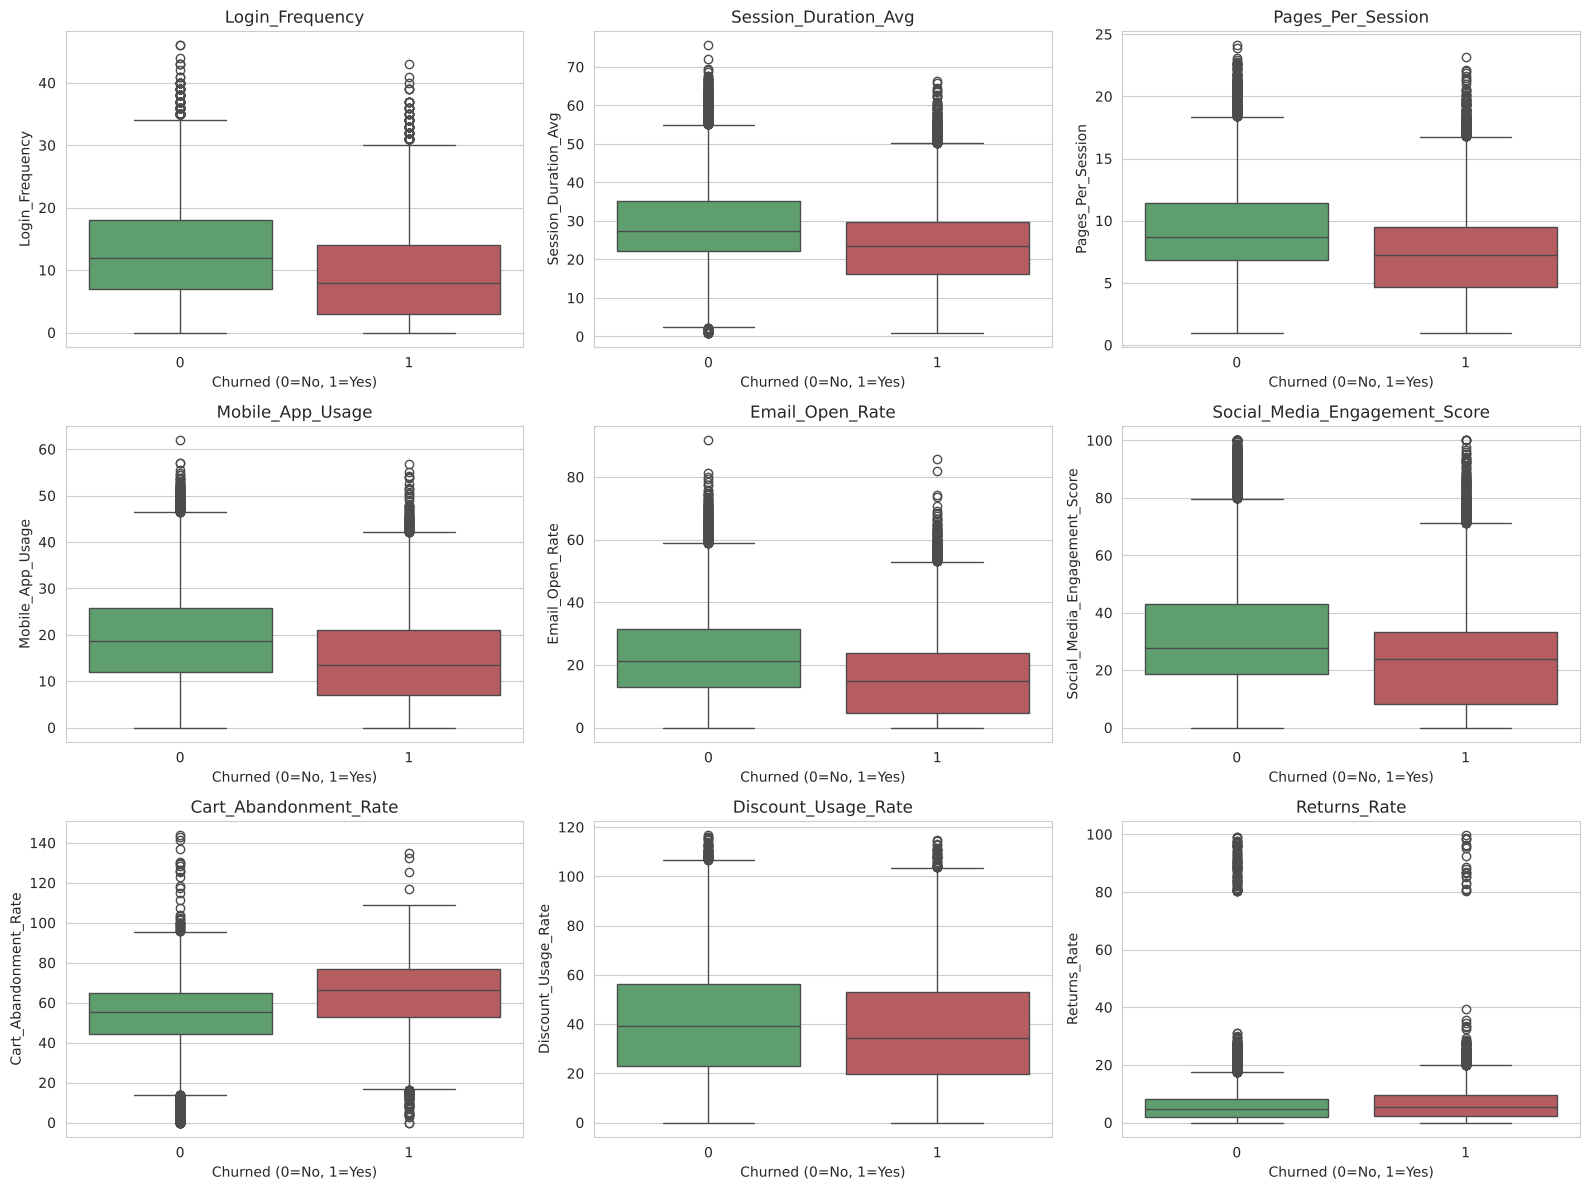

In [24]:
fig, axes = plt.subplots(3, 3, figsize=(16,12))
for ax, col in zip(axes.flatten(), behavior_cols):
    sns.boxplot(data=df_analysis, x="Churned", y=col, ax=ax, palette=["#55A868","#C44E52"])
    ax.set_title(col)
    ax.set_xlabel("Churned (0=No, 1=Yes)")
plt.tight_layout()
plt.show()


**Finding:** Perbandingan median behavioral metrics antara retained vs churned customer menunjukkan pola engagement dan purchase friction mana yang paling berbeda antar kedua kelompok (lihat tabel `comparison` di atas untuk angka pasti).

## 09. Customer Value Analysis

/tmp/ipykernel_197/855196031.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_analysis, x="Churned", y="Lifetime_Value", ax=axes[1], palette=["#55A868","#C44E52"])


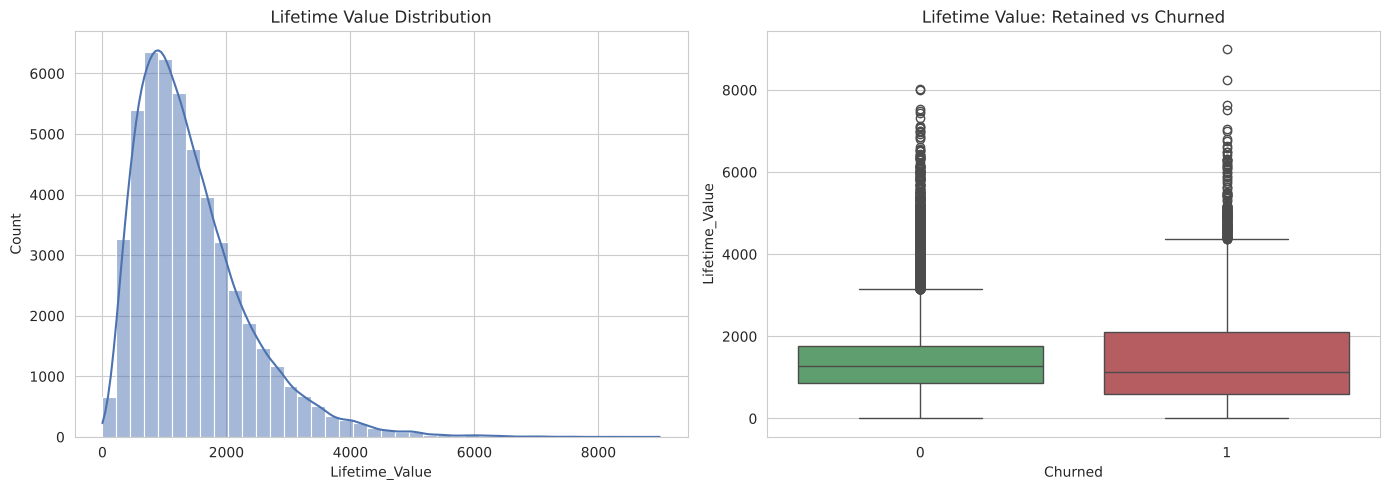

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.histplot(df_analysis["Lifetime_Value"], bins=40, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Lifetime Value Distribution")
sns.boxplot(data=df_analysis, x="Churned", y="Lifetime_Value", ax=axes[1], palette=["#55A868","#C44E52"])
axes[1].set_title("Lifetime Value: Retained vs Churned")
plt.tight_layout()
plt.show()


In [26]:
high_value_threshold = df_analysis["Lifetime_Value"].quantile(0.67)
high_value_churned = df_analysis[(df_analysis["Lifetime_Value"] >= high_value_threshold) & (df_analysis["Churned"]==1)]

print(f"High-value threshold (67th pct): {high_value_threshold:,.2f}")
print(f"High-value customers who churned: {len(high_value_churned):,}")
print(f"Potential LTV at risk from churned high-value customers: {high_value_churned['Lifetime_Value'].sum():,.2f}")


High-value threshold (67th pct): 1,632.81
High-value customers who churned: 5,473
Potential LTV at risk from churned high-value customers: 13,806,112.35


> **Business meaning:** Angka di atas menunjukkan potensi nilai bisnis yang sudah/berisiko hilang dari segmen pelanggan bernilai tinggi — ini menjadi dasar kuantitatif untuk memprioritaskan retention budget.

## 10. Customer Segmentation (RFM)

- **R (Recency):** `Days_Since_Last_Purchase` — semakin kecil = semakin recent
- **F (Frequency):** `Total_Purchases` — semakin besar = semakin frequent
- **M (Monetary):** `Lifetime_Value` — semakin besar = semakin bernilai


In [27]:
df_segment = df_analysis.copy()

df_segment["R_Score"] = pd.qcut(df_segment["Days_Since_Last_Purchase"].rank(method="first", ascending=False), 5, labels=[1,2,3,4,5]).astype(int)
df_segment["F_Score"] = pd.qcut(df_segment["Total_Purchases"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
df_segment["M_Score"] = pd.qcut(df_segment["Lifetime_Value"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)

df_segment["RFM_Score"] = df_segment["R_Score"].astype(str) + df_segment["F_Score"].astype(str) + df_segment["M_Score"].astype(str)
df_segment["RFM_Sum"] = df_segment[["R_Score","F_Score","M_Score"]].sum(axis=1)

df_segment[["R_Score","F_Score","M_Score","RFM_Score","RFM_Sum"]].head()


,R_Score,F_Score,M_Score,RFM_Score,RFM_Sum
0,2,2,2,222,6
1,1,5,3,153,9
2,4,2,3,423,9
3,1,4,5,145,10
4,1,5,5,155,11


In [28]:
def assign_segment(row):
    r, f, m = row["R_Score"], row["F_Score"], row["M_Score"]
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    elif r >= 3 and f >= 3 and m >= 3:
        return "Loyal Customers"
    elif r >= 4 and f <= 2:
        return "New Customers"
    elif r <= 2 and f >= 4 and m >= 4:
        return "Cannot Lose Them"
    elif r <= 2 and f >= 3:
        return "At Risk"
    elif r <= 2 and f <= 2 and m <= 2:
        return "Lost"
    elif r <= 3 and f <= 3:
        return "Hibernating"
    else:
        return "Potential Loyalists"

df_segment["Customer_Segment"] = df_segment.apply(assign_segment, axis=1)

segment_summary = df_segment.groupby("Customer_Segment").agg(
    customer_count=("Churned","size"),
    churn_rate=("Churned","mean"),
    avg_ltv=("Lifetime_Value","mean")
).sort_values("customer_count", ascending=False)
segment_summary


,customer_count,churn_rate,avg_ltv
Customer_Segment,,,
Loyal Customers,9218,0.211543,1815.839732
New Customers,7976,0.274448,827.207694
Hibernating,6647,0.339853,997.871182
At Risk,6253,0.209340,1297.123392
Lost,5976,0.541834,624.091223
Cannot Lose Them,5758,0.288468,2445.663025
Champions,5741,0.280613,2455.768504
Potential Loyalists,2431,0.095845,839.600671


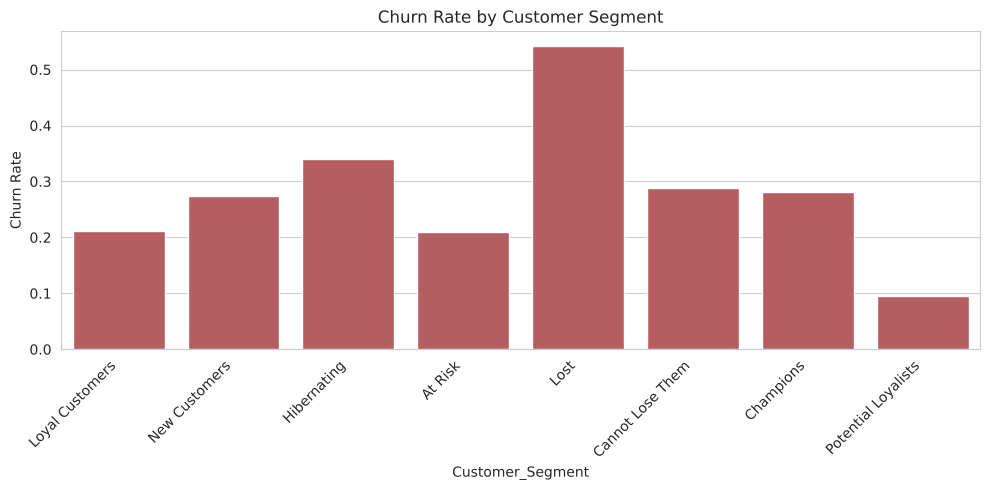

In [29]:
plt.figure(figsize=(10,5))
sns.barplot(x=segment_summary.index, y=segment_summary["churn_rate"], color="#C44E52")
plt.xticks(rotation=45, ha="right")
plt.title("Churn Rate by Customer Segment")
plt.ylabel("Churn Rate")
plt.tight_layout()
plt.show()


> **Business priority:** Segmen dengan churn rate tinggi DAN avg_ltv tinggi (umumnya *Cannot Lose Them* / *At Risk*) adalah prioritas retention tertinggi.

## 11. Churn Driver Analysis

### Level 1 — Correlation

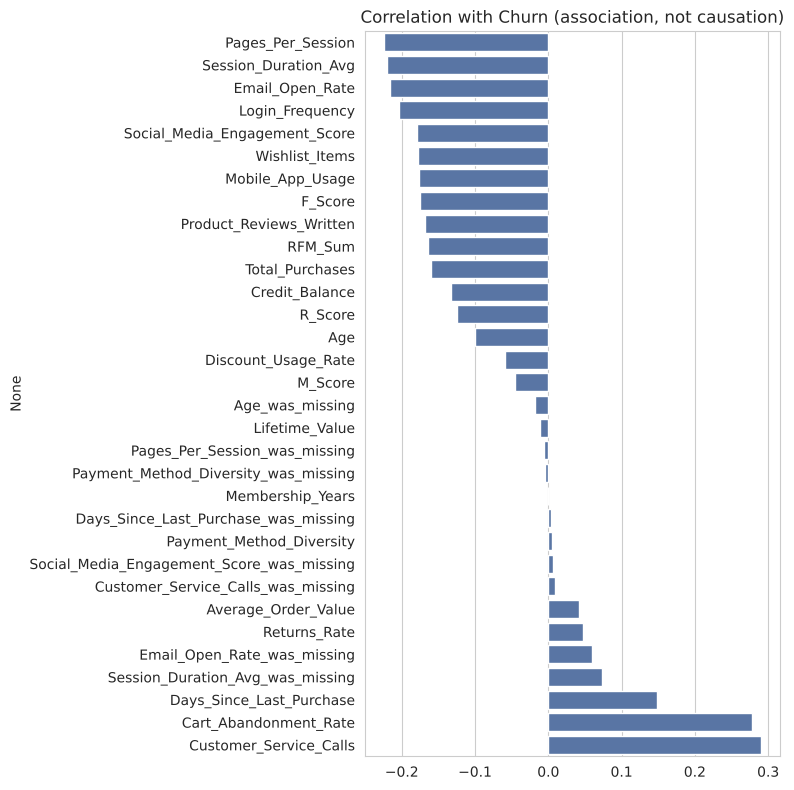

Pages_Per_Session                           -0.224708
Session_Duration_Avg                        -0.219512
Email_Open_Rate                             -0.216233
Login_Frequency                             -0.204379
Social_Media_Engagement_Score               -0.179829
Wishlist_Items                              -0.177308
Mobile_App_Usage                            -0.176641
F_Score                                     -0.175522
Product_Reviews_Written                     -0.168212
RFM_Sum                                     -0.164266
Total_Purchases                             -0.160029
Credit_Balance                              -0.132607
R_Score                                     -0.124076
Age                                         -0.100511
Discount_Usage_Rate                         -0.058823
M_Score                                     -0.045924
Age_was_missing                             -0.018248
Lifetime_Value                              -0.010684
Pages_Per_Session_was_missin

In [30]:
corr = (
    df_segment.select_dtypes(include=np.number)
    .corr()["Churned"]
    .drop("Churned")
    .sort_values()
)
plt.figure(figsize=(8,8))
sns.barplot(x=corr.values, y=corr.index, color="#4C72B0")
plt.title("Correlation with Churn (association, not causation)")
plt.tight_layout()
plt.show()
corr


> **Interpretation rule:** correlation menunjukkan association, bukan causality.

### Level 2 — Group Comparison

In [31]:
driver_numeric_cols = [c for c in df_segment.select_dtypes(include=np.number).columns if c != "Churned"]
group_comparison = (
    df_segment.groupby("Churned")[driver_numeric_cols]
    .median()
    .T
)
group_comparison.columns = ["Retained_Median", "Churned_Median"]
group_comparison["Abs_Difference"] = (group_comparison["Churned_Median"] - group_comparison["Retained_Median"]).abs()
group_comparison.sort_values("Abs_Difference", ascending=False).head(15)


,Retained_Median,Churned_Median,Abs_Difference
Credit_Balance,1833.000,1355.000,478.00
Lifetime_Value,1266.790,1132.730,134.06
Average_Order_Value,108.935,124.395,15.46
Cart_Abandonment_Rate,55.500,66.600,11.10
Email_Open_Rate,21.100,14.900,6.20
Mobile_App_Usage,18.700,13.500,5.20
Discount_Usage_Rate,39.300,34.300,5.00
Login_Frequency,12.000,8.000,4.00
Social_Media_Engagement_Score,27.600,23.800,3.80
Session_Duration_Avg,27.400,23.600,3.80


### Level 3 — Statistical Testing

In [32]:
test_cols = ["Days_Since_Last_Purchase", "Login_Frequency", "Total_Purchases",
             "Cart_Abandonment_Rate", "Lifetime_Value", "Email_Open_Rate"]

results = []
for col in test_cols:
    churned_vals = df_segment.loc[df_segment["Churned"]==1, col].dropna()
    retained_vals = df_segment.loc[df_segment["Churned"]==0, col].dropna()
    stat, p = stats.mannwhitneyu(churned_vals, retained_vals, alternative="two-sided")
    # effect size (rank-biserial correlation approximation)
    n1, n2 = len(churned_vals), len(retained_vals)
    effect_size = 1 - (2*stat) / (n1*n2)
    results.append({"variable": col, "p_value": p, "effect_size_r": round(effect_size,4),
                     "significant": p < 0.05})

stat_results = pd.DataFrame(results)
stat_results


,variable,p_value,effect_size_r,significant
0,Days_Since_Last_Purchase,5.846009e-185,-0.1651,True
1,Login_Frequency,0.000000e+00,0.2716,True
2,Total_Purchases,0.000000e+00,0.2393,True
3,Cart_Abandonment_Rate,0.000000e+00,-0.3556,True
4,Lifetime_Value,3.905710e-35,0.0704,True
5,Email_Open_Rate,0.000000e+00,0.2873,True


> Tujuan uji ini bukan sekadar mencari `p < 0.05`, melainkan melihat **magnitude** (effect size) dan **arah** perbedaan untuk menilai practical significance, lalu menerjemahkannya ke business interpretation.

### Level 4 — Predictive Model (Analytical Support)

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, roc_curve

model_features = ["Age","Membership_Years","Login_Frequency","Session_Duration_Avg",
                   "Pages_Per_Session","Cart_Abandonment_Rate","Wishlist_Items",
                   "Total_Purchases","Average_Order_Value","Days_Since_Last_Purchase",
                   "Discount_Usage_Rate","Returns_Rate","Email_Open_Rate",
                   "Social_Media_Engagement_Score","Mobile_App_Usage","Lifetime_Value"]

df_model = df_segment.dropna(subset=model_features + ["Churned"]).copy()
X = df_model[model_features]
y = df_model["Churned"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg.fit(X_train_scaled, y_train)

rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)

print("Train/test split done:", X_train.shape, X_test.shape)


Train/test split done: (37500, 16) (12500, 16)


In [34]:
# Logistic Regression evaluation
y_pred_lr = logreg.predict(X_test_scaled)
y_proba_lr = logreg.predict_proba(X_test_scaled)[:,1]

print("Logistic Regression Report:")
print(classification_report(y_test, y_pred_lr))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_lr), 4))


Logistic Regression Report:
              precision    recall  f1-score   support

           0       0.78      0.94      0.86      8888
           1       0.71      0.36      0.48      3612

    accuracy                           0.77     12500
   macro avg       0.75      0.65      0.67     12500
weighted avg       0.76      0.77      0.75     12500

ROC-AUC: 0.7655


In [35]:
# Random Forest evaluation
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:,1]

print("Random Forest Report:")
print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_rf), 4))


Random Forest Report:
              precision    recall  f1-score   support

           0       0.83      0.96      0.89      8888
           1       0.83      0.53      0.65      3612

    accuracy                           0.83     12500
   macro avg       0.83      0.74      0.77     12500
weighted avg       0.83      0.83      0.82     12500

ROC-AUC: 0.8757


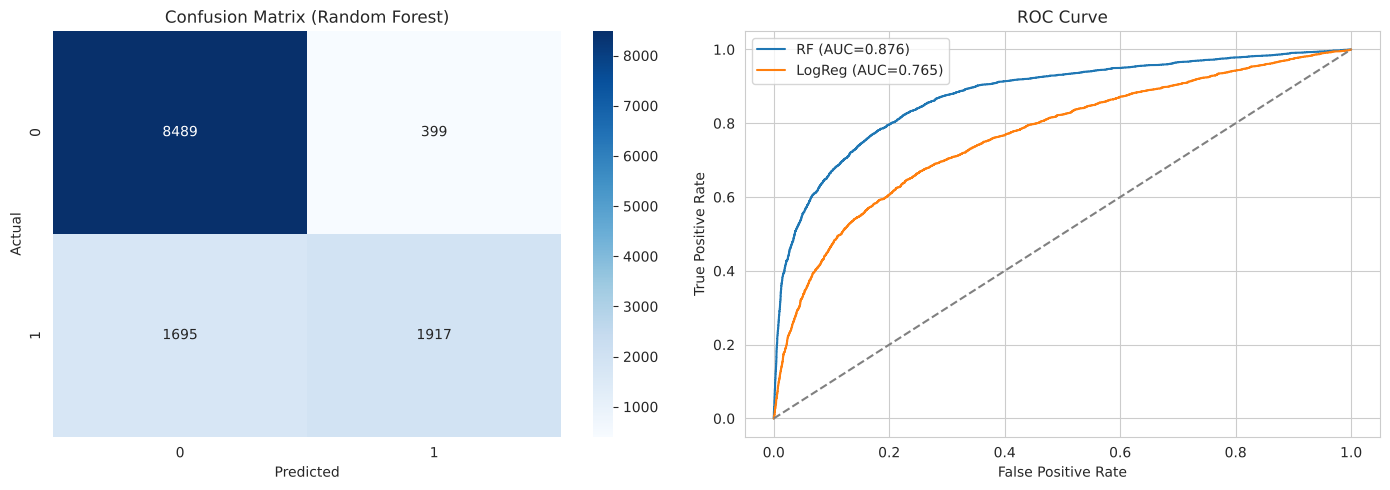

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix (Random Forest)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

fpr, tpr, _ = roc_curve(y_test, y_proba_rf)
axes[1].plot(fpr, tpr, label=f"RF (AUC={roc_auc_score(y_test, y_proba_rf):.3f})")
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
axes[1].plot(fpr_lr, tpr_lr, label=f"LogReg (AUC={roc_auc_score(y_test, y_proba_lr):.3f})")
axes[1].plot([0,1],[0,1],"--", color="gray")
axes[1].set_title("ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()
plt.tight_layout()
plt.show()


> **Note on threshold:** default 0.5 tidak otomatis dipakai untuk keputusan bisnis. Karena kehilangan high-risk/high-value customer costly, recall pada kelas churn diprioritaskan — threshold produksi sebaiknya ditentukan berdasarkan business cost (biaya retention campaign vs. nilai customer yang hilang), bukan default statistik.

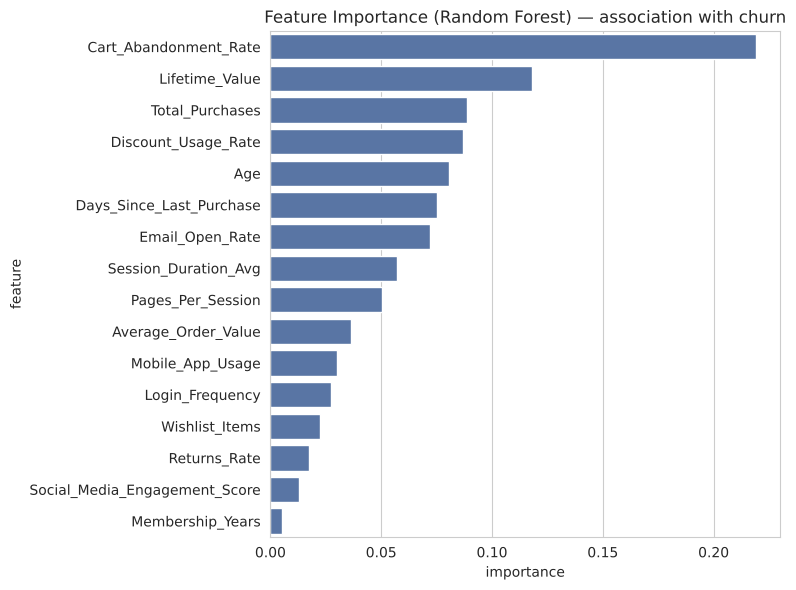

,feature,importance
5,Cart_Abandonment_Rate,0.219009
15,Lifetime_Value,0.118257
7,Total_Purchases,0.088721
10,Discount_Usage_Rate,0.086688
0,Age,0.080650
9,Days_Since_Last_Purchase,0.075201
12,Email_Open_Rate,0.071909
3,Session_Duration_Avg,0.057176
4,Pages_Per_Session,0.050575
8,Average_Order_Value,0.036583


In [37]:
feature_importance = pd.DataFrame({
    "feature": model_features,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(x="importance", y="feature", data=feature_importance, color="#4C72B0")
plt.title("Feature Importance (Random Forest) — association with churn")
plt.tight_layout()
plt.show()
feature_importance


**Feature interpretation:** Fitur dengan importance tertinggi menunjukkan **asosiasi kuat** dengan churn dalam model ini — bukan bukti bahwa fitur tersebut *menyebabkan* churn. Misalnya, "Days_Since_Last_Purchase appears to be an important predictor of churn in this model" — bukan "menyebabkan churn".

## 12. Risk × Value Prioritization

Dua dimensi: **Customer Value** (X) dan **Churn Risk** (Y), menghasilkan matrix 2x2 untuk prioritas retention.


In [38]:
# Churn risk proxy: predicted probability from Random Forest, scored on full cleaned dataset
X_full = df_model[model_features]
df_model["Churn_Risk_Score"] = rf.predict_proba(X_full)[:,1]

risk_median = df_model["Churn_Risk_Score"].median()
value_median = df_model["Lifetime_Value"].median()

df_model["Risk_Level"] = np.where(df_model["Churn_Risk_Score"] >= risk_median, "High Risk", "Low Risk")
df_model["Value_Level"] = np.where(df_model["Lifetime_Value"] >= value_median, "High Value", "Low Value")
df_model["Priority_Segment"] = df_model["Value_Level"] + " / " + df_model["Risk_Level"]

priority_table = df_model.groupby("Priority_Segment").agg(
    customer_count=("Churned","size"),
    actual_churn_rate=("Churned","mean"),
    avg_ltv=("Lifetime_Value","mean"),
    avg_risk_score=("Churn_Risk_Score","mean")
).sort_values("avg_ltv", ascending=False)
priority_table


,customer_count,actual_churn_rate,avg_ltv,avg_risk_score
Priority_Segment,,,,
High Value / High Risk,13309,0.456608,2442.251538,0.410671
High Value / Low Risk,11691,0.058079,1732.816509,0.109413
Low Value / Low Risk,13309,0.051018,878.593075,0.109762
Low Value / High Risk,11691,0.600034,648.005803,0.531173


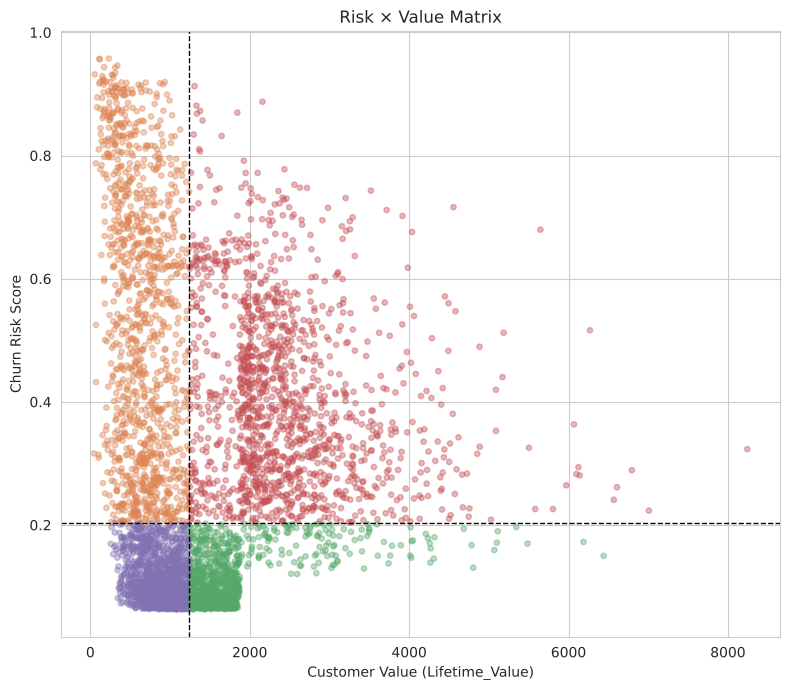

In [39]:
plt.figure(figsize=(8,7))
sample = df_model.sample(min(5000, len(df_model)), random_state=RANDOM_STATE)
colors = sample["Priority_Segment"].map({
    "High Value / High Risk": "#C44E52",
    "High Value / Low Risk": "#55A868",
    "Low Value / High Risk": "#DD8452",
    "Low Value / Low Risk": "#8172B2"
})
plt.scatter(sample["Lifetime_Value"], sample["Churn_Risk_Score"], c=colors, alpha=0.4, s=15)
plt.axvline(value_median, color="black", linestyle="--", linewidth=1)
plt.axhline(risk_median, color="black", linestyle="--", linewidth=1)
plt.xlabel("Customer Value (Lifetime_Value)")
plt.ylabel("Churn Risk Score")
plt.title("Risk × Value Matrix")
plt.tight_layout()
plt.show()


**Retention Priority Framework**

| Segment | Churn Risk | Customer Value | Priority | Strategy |
|---|---|---|---|---|
| High Value + High Risk | High | High | **Critical (P1)** | Save / personal retention outreach |
| High Value + Low Risk | Low | High | High (P2) | Loyalty program / maintain |
| Low Value + High Risk | High | Low | Medium (P2) | Low-cost automated re-engagement |
| Low Value + Low Risk | Low | Low | Low (P3) | Standard lifecycle messaging |


## 13. Business Insights

**Insight 1 — Purchase Recency as Early Warning**

- **Finding:** Customer dengan recency lebih panjang (lama tidak membeli) cenderung menunjukkan churn rate lebih tinggi.
- **Evidence:** Lihat tabel `recency_churn` di Section 07.5 — churn rate meningkat progresif seiring bertambahnya recency band.
- **Interpretation:** Inaktivitas pembelian tampaknya menjadi sinyal awal disengagement pelanggan.
- **Business Implication:** Menunggu hingga customer benar-benar churn mengurangi peluang retention.
- **Action:** Implementasikan automated retention trigger berbasis inaktivitas pembelian.

**Insight 2 — Value Concentration of Churn Risk**

- **Finding:** Sebagian churn terjadi pada segmen pelanggan bernilai tinggi (lihat Section 09 & 12).
- **Evidence:** `high_value_churned` menunjukkan jumlah dan total LTV pelanggan bernilai tinggi yang churn.
- **Interpretation:** Risiko churn tidak merata — sebagian terkonsentrasi pada customer yang secara ekonomi penting.
- **Business Implication:** Kehilangan customer ini berdampak disproporsional terhadap revenue dibanding rata-rata.
- **Action:** Prioritaskan budget retention pada segmen High Value / High Risk (Section 12).

**Insight 3 — Engagement Metrics sebagai Behavioral Signal**

- **Finding:** Metrik engagement (login frequency, session duration, email open rate) menunjukkan perbedaan median antara retained dan churned customer (Section 08 & 11).
- **Evidence:** Tabel `comparison` dan `group_comparison`, serta hasil uji Mann-Whitney (Section 11, Level 3).
- **Interpretation:** Penurunan engagement berasosiasi dengan peningkatan churn risk.
- **Business Implication:** Engagement dapat digunakan sebagai leading indicator, bukan hanya purchase data.
- **Action:** Pantau engagement score sebagai bagian dari early warning dashboard.

**Insight 4 — Cart Abandonment & Purchase Friction**

- **Finding:** Cart abandonment rate menunjukkan asosiasi dengan churn (lihat korelasi & feature importance, Section 11).
- **Interpretation:** Friksi dalam proses checkout berasosiasi dengan ketidakpuasan/disengagement.
- **Business Implication:** Mengabaikan cart abandonment dapat membiarkan revenue yang "nyaris terjadi" hilang.
- **Action:** Targeted reminder & checkout optimization, bukan diskon massal untuk semua customer.


## 14. Business Recommendations

**Recommendation 1 — Early Warning System**
Kombinasikan `Days_Since_Last_Purchase` + `Login_Frequency` + `Total_Purchases` menjadi composite early-warning score untuk mendeteksi pelanggan yang mulai disengaged sebelum benar-benar churn.

**Recommendation 2 — VIP At-Risk Retention**
Untuk segmen High Lifetime Value + High Churn Risk (Section 12): personalized offer, loyalty benefit eksklusif, product recommendation yang relevan, dan customer outreach langsung (bukan automated generic email).

**Recommendation 3 — Automated Re-Engagement (tiered by inactivity)**
- 30 hari inaktif → reminder otomatis
- 60 hari inaktif → personalized recommendation
- 90+ hari inaktif → win-back campaign

Threshold ini harus disesuaikan lagi dengan distribusi recency aktual perusahaan dan hasil uji A/B.

**Recommendation 4 — Cart Abandonment Intervention**
Reminder terarah, personalized recommendation, checkout optimization, dan targeted incentive — bukan diskon untuk seluruh customer base.

**Recommendation 5 — Lifecycle Segmentation**
Perlakukan tiap tahap lifecycle (New → Active → Engaged → At Risk → Churned) dengan treatment komunikasi dan insentif yang berbeda, bukan satu strategi untuk semua.

### Recommendation Prioritization

| Recommendation | Expected Impact | Effort | Priority |
|---|---|---|---|
| Early Warning System | High | Medium | P1 |
| VIP At-Risk Retention | High | Medium | P1 |
| Automated Re-Engagement | Medium/High | Low/Medium | P1 |
| Cart Abandonment Intervention | Medium | Medium | P2 |
| Lifecycle Segmentation Rollout | Medium | High | P2 |


## 15. Executive Summary

In [40]:
n_customers = df_analysis.shape[0]
top_priority_segment = priority_table.sort_values("avg_ltv", ascending=False).index[0]
top_priority_count = priority_table.loc[top_priority_segment, "customer_count"]
top_driver = feature_importance.iloc[0]["feature"]

print(f"Total customers analyzed: {n_customers:,}")
print(f"Overall churn rate: {churn_rate:.2%}")
print(f"Top churn driver (by model importance): {top_driver}")
print(f"Highest-priority segment: {top_priority_segment} ({top_priority_count:,} customers)")


Total customers analyzed: 50,000
Overall churn rate: 28.90%
Top churn driver (by model importance): Cart_Abandonment_Rate
Highest-priority segment: High Value / High Risk (13,309 customers)


> ### Executive Summary
>
> The dataset contains **50,000 customers** with an overall churn rate shown above. The analysis indicates that purchase recency, engagement metrics (login frequency, session duration, email open rate), and cart abandonment behavior are strongly associated with churn.
>
> The highest-priority segment is **High Value / High Risk** customers, characterized by elevated predicted churn probability combined with above-median Lifetime Value, representing the customers above in count.
>
> The business should prioritize:
> 1. Deploying an early-warning system based on recency, login frequency, and purchase frequency.
> 2. Launching personalized VIP retention outreach for the High Value / High Risk segment.
> 3. Automating tiered re-engagement campaigns (30/60/90-day inactivity triggers).
>
> These initiatives should be monitored using: churn rate, retention rate, reactivation rate, customer lifetime value, and repeat purchase rate.


## 16. KPI Monitoring Framework

**Customer Health:** Churn Rate · Retention Rate · Active Customer Rate · Reactivation Rate

**Engagement:** Login Frequency · Session Duration · Email Open Rate · Mobile App Usage

**Purchase:** Repeat Purchase Rate · Purchase Frequency · Days Since Last Purchase · Average Order Value

**Value:** Lifetime Value · Revenue from Retained Customers · Value of At-Risk Customers

### Final Priority Table

| Priority | Customer Segment | Size | Churn Rate | Avg LTV | Business Risk | Recommended Action |
|---|---|---:|---:|---:|---|---|
| P1 | High Value / High Risk | see `priority_table` | see `priority_table` | see `priority_table` | Critical | VIP Retention |
| P1 | Low Value / High Risk | see `priority_table` | see `priority_table` | see `priority_table` | High | Automated Re-engagement |
| P2 | High Value / Low Risk | see `priority_table` | see `priority_table` | see `priority_table` | Medium | Loyalty Program |
| P3 | Low Value / Low Risk | see `priority_table` | see `priority_table` | see `priority_table` | Low | Standard Lifecycle |

---
## Appendix

- Raw data: `df` — unmodified source file
- Cleaned data: `df_clean` — missing values treated, no rows dropped
- Analysis data: `df_analysis` — feature-enriched (age/recency/value bands)
- Segmentation data: `df_segment` — RFM scores & customer segments
- Model data: `df_model` — rows with complete model features, includes risk scores

**Guardrails applied throughout this notebook:**
1. Correlation was not treated as causation.
2. Outliers were investigated, not blindly removed.
3. Missing values were treated based on business meaning, not blanket median imputation.
4. Country/city rankings used a minimum sample-size rule.
5. Model evaluation used precision/recall/F1/ROC-AUC, not accuracy alone.
6. Feature importance was interpreted as association, not causal impact.
7. Discounts were not recommended uniformly to all customers.
8. Prioritization combined both churn risk and customer value.
